# Klasifikasi Citra Sepatu: Berantakan vs Rapi

## 1. Import Library

In [16]:
import os
import io
import glob
import zipfile

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

## 2. Konfigurasi

In [17]:
FILE_ZIP = None                     # None = otomatis cari *.zip di data/image
FOLDER_DATA = "data/image"
UKURAN_RESIZE = (256, 256)          # semua gambar disamakan ukurannya
EKSTENSI = (".jpg", ".jpeg", ".png", ".bmp", ".webp", ".jfif")
FILE_OUTPUT = "data/processed/fitur_rgb.csv"

if FILE_ZIP is None:
    daftar_zip = glob.glob(os.path.join(FOLDER_DATA, "*.zip"))
    if not daftar_zip:
        raise FileNotFoundError(
            f"Tidak ada zip di {os.path.abspath(FOLDER_DATA)}. "
            "Isi FILE_ZIP dengan path lengkap file zip."
        )
    FILE_ZIP = daftar_zip[0]

print("Folder kerja :", os.getcwd())
print("File zip     :", os.path.abspath(FILE_ZIP))

Folder kerja : c:\project\image-classification
File zip     : c:\project\image-classification\data\image\berantakan.zip


## 3. Membaca Data
### 3.1 Jumlah gambar di dalam zip

In [18]:
def tentukan_label(path):
    teks = path.lower().replace("\\", "/")
    if "berantakan" in teks or "messy" in teks:
        return "berantakan"
    if "rapi" in teks or "neat" in teks or "tidy" in teks:
        return "rapi"
    return None

arsip = zipfile.ZipFile(FILE_ZIP)   # zip dibuka sekali, dipakai di semua sel

data = []
for nama in sorted(arsip.namelist()):
    base = os.path.basename(nama)
    if nama.endswith("/") or "__MACOSX" in nama or base.startswith("._"):
        continue                    # lewati folder & file sampah Mac
    if base.lower().endswith(EKSTENSI):
        data.append({"path": nama, "label": tentukan_label(nama)})

df = pd.DataFrame(data, columns=["path", "label"])

print("Total gambar :", len(df))
print()
print(df["label"].value_counts(dropna=False))

if len(df) == 0:
    print("\nTidak ada gambar terbaca. Isi zip (20 entri pertama):")
    for n in arsip.namelist()[:20]:
        print(" ", n)
elif df["label"].isna().any():
    print("\nPERINGATAN: ada gambar yang labelnya tidak dikenali")

Total gambar : 97

label
berantakan    97
Name: count, dtype: int64


### 3.2 Contoh gambar asli

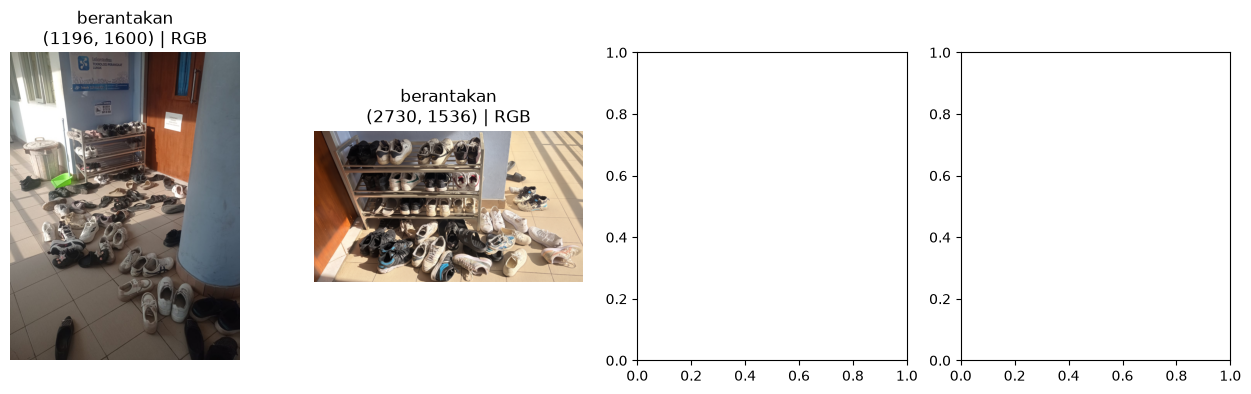

In [19]:
def buka_gambar(nama):
    """Baca gambar langsung dari zip ke memori (tanpa ekstrak)."""
    return Image.open(io.BytesIO(arsip.read(nama)))

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
contoh = pd.concat([df[df.label == "berantakan"].head(2), df[df.label == "rapi"].head(2)])
for ax, (_, row) in zip(axes, contoh.iterrows()):
    img = buka_gambar(row["path"])
    ax.imshow(img)
    ax.set_title(f"{row['label']}\n{img.size} | {img.mode}")
    ax.axis("off")
plt.show()

## 4. Preprocessing
1. **Konversi ke RGB** — gambar PNG (RGBA) atau grayscale disamakan menjadi 3 kanal.
2. **Resize** — semua gambar disamakan ukurannya menjadi 256 × 256 piksel.

In [20]:
def preprocessing(nama):
    img = buka_gambar(nama)
    img = img.convert("RGB")                  # 1. konversi RGB
    img = img.resize(UKURAN_RESIZE)           # 2. resize
    return np.array(img, dtype=np.float64)    # array (256, 256, 3)

arr = preprocessing(df.loc[0, "path"])
print("Shape setelah preprocessing:", arr.shape)
print("Nilai piksel min - max     :", arr.min(), "-", arr.max())

Shape setelah preprocessing: (256, 256, 3)
Nilai piksel min - max     : 6.0 - 255.0


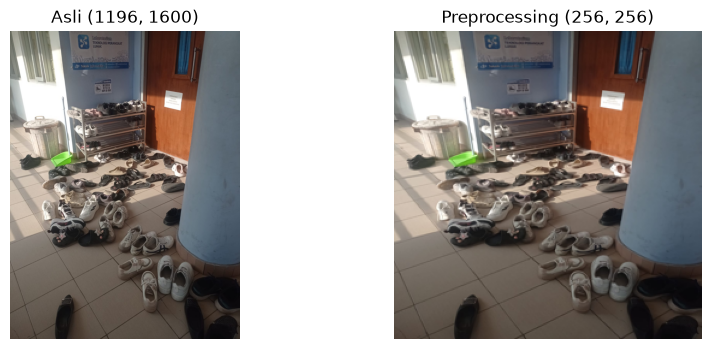

In [21]:
# Sebelum vs sesudah preprocessing
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
asli = buka_gambar(df.loc[0, "path"])
axes[0].imshow(asli);                   axes[0].set_title(f"Asli {asli.size}")
axes[1].imshow(arr.astype(np.uint8));   axes[1].set_title(f"Preprocessing {UKURAN_RESIZE}")
for ax in axes: ax.axis("off")
plt.show()

In [22]:
# Melihat nilai piksel asli (setelah preprocessing) sebelum dihitung mean-nya
idx = 0                                   # ganti untuk melihat gambar lain
arr = preprocessing(df.loc[idx, "path"])

R = arr[:, :, 0]
G = arr[:, :, 1]
B = arr[:, :, 2]

print("Gambar :", df.loc[idx, "path"], "| label:", df.loc[idx, "label"])
print("Ukuran tiap kanal :", R.shape, "=", R.size, "piksel\n")

n = 5   # tampilkan potongan 5x5 piksel kiri-atas
for nama, kanal in [("R", R), ("G", G), ("B", B)]:
    print(f"Kanal {nama} ({n}x{n} piksel pertama):")
    print(pd.DataFrame(kanal[:n, :n].astype(int)).to_string())
    print()

# Contoh perhitungan mean secara manual
for nama, kanal in [("R", R), ("G", G), ("B", B)]:
    total = kanal.sum()
    print(f"mean_{nama.lower()} = {total:.0f} / {kanal.size} = {total / kanal.size:.4f}")

Gambar : berantakan/24-003 Berantakan 2.jpg | label: berantakan
Ukuran tiap kanal : (256, 256) = 65536 piksel

Kanal R (5x5 piksel pertama):
     0    1    2    3    4
0   98  120  157  156  156
1  101  113  156  157  156
2  101  107  148  159  157
3   96  104  138  161  159
4   95  104  125  161  161

Kanal G (5x5 piksel pertama):
     0    1    2    3    4
0  101  122  158  156  156
1  104  115  157  157  156
2  105  110  150  159  157
3  102  108  141  161  159
4  101  108  128  162  161

Kanal B (5x5 piksel pertama):
    0    1    2    3    4
0  90  110  144  144  144
1  93  103  143  145  144
2  93   97  136  146  145
3  90   95  126  149  147
4  89   95  114  149  149

mean_r = 7113552 / 65536 = 108.5442
mean_g = 6645077 / 65536 = 101.3958
mean_b = 6326362 / 65536 = 96.5326


In [23]:
# Simpan piksel SEMUA gambar ke satu CSV
semua = []
for i, row in df.iterrows():
    a = preprocessing(row["path"])
    br, kl = np.indices(a.shape[:2])
    semua.append(pd.DataFrame({
        "id": i + 1,
        "baris": br.ravel(),
        "kolom": kl.ravel(),
        "R": a[:, :, 0].ravel().astype(int),
        "G": a[:, :, 1].ravel().astype(int),
        "B": a[:, :, 2].ravel().astype(int),
        "label": row["label"],
    }))

piksel_semua = pd.concat(semua, ignore_index=True)
os.makedirs("data/processed", exist_ok=True)
piksel_semua.to_csv("data/processed/piksel_semua.csv", index=False)
print("Jumlah baris:", len(piksel_semua))

Jumlah baris: 6356992


## 5. Ekstraksi Fitur Warna (Mean R, G, B)
- `mean_r` = rata-rata nilai piksel kanal **Red** (0–255)
- `mean_g` = rata-rata nilai piksel kanal **Green** (0–255)
- `mean_b` = rata-rata nilai piksel kanal **Blue** (0–255)

In [24]:
def ekstraksi_fitur(arr):
    return arr[:, :, 0].mean(), arr[:, :, 1].mean(), arr[:, :, 2].mean()

hasil = []
for i, row in df.iterrows():
    r, g, b = ekstraksi_fitur(preprocessing(row["path"]))
    hasil.append({
        "id": i + 1,
        "mean_r": round(r, 4),
        "mean_g": round(g, 4),
        "mean_b": round(b, 4),
        "label": row["label"],
    })

tabel = pd.DataFrame(hasil)
# pd.set_option("display.max_rows", None)
tabel.head()

,id,mean_r,mean_g,mean_b,label
0,1,108.5442,101.3958,96.5326,berantakan
1,2,149.4176,129.9941,112.1718,berantakan
2,3,144.5782,109.8351,85.6104,berantakan
3,4,120.5385,112.6790,109.4066,berantakan
4,5,126.6296,119.9131,116.6886,berantakan


In [25]:
# Tambahan fitur: standar deviasi R, G, B
std_r, std_g, std_b = [], [], []
for i, row in df.iterrows():
    arr = preprocessing(row["path"])
    std_r.append(round(arr[:, :, 0].std(), 4))
    std_g.append(round(arr[:, :, 1].std(), 4))
    std_b.append(round(arr[:, :, 2].std(), 4))

# sisipkan kolom std sebelum kolom label
posisi = tabel.columns.get_loc("label")
tabel.insert(posisi, "std_r", std_r)
tabel.insert(posisi + 1, "std_g", std_g)
tabel.insert(posisi + 2, "std_b", std_b)

tabel.head()

,id,mean_r,mean_g,mean_b,std_r,std_g,std_b,label
0,1,108.5442,101.3958,96.5326,55.0561,53.7121,52.8137,berantakan
1,2,149.4176,129.9941,112.1718,72.8466,69.7848,63.4107,berantakan
2,3,144.5782,109.8351,85.6104,70.3410,57.7117,53.7634,berantakan
3,4,120.5385,112.6790,109.4066,53.0531,51.0577,50.7295,berantakan
4,5,126.6296,119.9131,116.6886,54.1044,50.0877,48.7256,berantakan


In [26]:
os.makedirs(os.path.dirname(FILE_OUTPUT), exist_ok=True)
tabel.to_csv(FILE_OUTPUT, index=False)
print("Tabel disimpan ke:", os.path.abspath(FILE_OUTPUT))

Tabel disimpan ke: c:\project\image-classification\data\processed\fitur_rgb.csv


Jumlah citra grayscale : 97
Level keabuan          : 2^8 = 256 (nilai 0 - 255)

Gambar : berantakan/24-003 Berantakan 2.jpg | label: berantakan
Shape RGB  : (256, 256, 3) -> Shape gray: (256, 256)
Tipe data  : uint8 | min: 6 | max: 255

Piksel (0,0): R=98, G=101, B=90
Gray = 0.299*98 + 0.587*101 + 0.114*90 = 98.85 -> 99

Nilai gray (5x5 piksel pertama):
     0    1    2    3    4
0   99  120  156  155  155
1  102  113  155  156  155
2  102  108  148  158  156
3   99  105  138  160  158
4   98  105  126  160  160


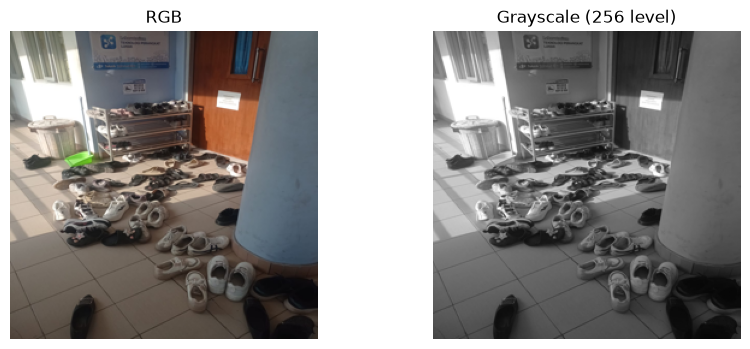

In [27]:
def rgb_ke_gray(arr):
    R, G, B = arr[:, :, 0], arr[:, :, 1], arr[:, :, 2]
    gray = 0.299 * R + 0.587 * G + 0.114 * B
    return np.clip(np.round(gray), 0, 255).astype(np.uint8)   # 8 bit: 0-255

# Konversi semua gambar (hasil preprocessing) ke grayscale
citra_gray = {}
for i, row in df.iterrows():
    citra_gray[i + 1] = rgb_ke_gray(preprocessing(row["path"]))

print("Jumlah citra grayscale :", len(citra_gray))
print("Level keabuan          : 2^8 =", 2**8, "(nilai 0 - 255)")

# Contoh satu gambar
idx = 0
arr = preprocessing(df.loc[idx, "path"])
gray = citra_gray[idx + 1]

print("\nGambar :", df.loc[idx, "path"], "| label:", df.loc[idx, "label"])
print("Shape RGB  :", arr.shape, "-> Shape gray:", gray.shape)
print("Tipe data  :", gray.dtype, "| min:", gray.min(), "| max:", gray.max())

# Contoh hitung manual 1 piksel (kiri-atas)
r, g, b = arr[0, 0]
print(f"\nPiksel (0,0): R={r:.0f}, G={g:.0f}, B={b:.0f}")
print(f"Gray = 0.299*{r:.0f} + 0.587*{g:.0f} + 0.114*{b:.0f} = {0.299*r + 0.587*g + 0.114*b:.2f} -> {gray[0, 0]}")

# Potongan 5x5 nilai gray
n = 5
print(f"\nNilai gray ({n}x{n} piksel pertama):")
print(pd.DataFrame(gray[:n, :n]).to_string())

# Tampilkan RGB vs grayscale
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(arr.astype(np.uint8));           axes[0].set_title("RGB")
axes[1].imshow(gray, cmap="gray", vmin=0, vmax=255); axes[1].set_title("Grayscale (256 level)")
for ax in axes: ax.axis("off")
plt.show()

In [28]:
def buat_glcm(gray, levels=256, dx=1, dy=0):
    """GLCM mentah. dx=1, dy=0 -> d=1, θ=0° (tetangga kanan)."""
    h, w = gray.shape
    ref = gray[0:h - dy, 0:w - dx].ravel().astype(np.int64)   # piksel referensi
    tet = gray[dy:h, dx:w].ravel().astype(np.int64)           # piksel tetangga
    glcm = np.zeros((levels, levels), dtype=np.int64)
    np.add.at(glcm, (ref, tet), 1)                            # tabulasi frekuensi pasangan
    return glcm

def fitur_glcm(glcm):
    P = glcm / glcm.sum()                                     # normalisasi -> P(i,j)
    N = P.shape[0]
    i, j = np.indices((N, N))

    contrast    = np.sum((i - j) ** 2 * P)                    # Pers. (6)
    energy      = np.sum(P ** 2)                              # Pers. (8)
    homogeneity = np.sum(P / (1 + np.abs(i - j)))             # Pers. (9)
    nz = P[P > 0]
    entropy     = -np.sum(nz * np.log2(nz))                   # Pers. (5)

    mu_i = np.sum(i * P)
    mu_j = np.sum(j * P)
    sd_i = np.sqrt(np.sum((i - mu_i) ** 2 * P))
    sd_j = np.sqrt(np.sum((j - mu_j) ** 2 * P))
    correlation = np.sum((i - mu_i) * (j - mu_j) * P) / (sd_i * sd_j) if sd_i * sd_j > 0 else 1.0  # Pers. (7)

    return {"contrast": contrast, "energy": energy, "correlation": correlation,
            "entropy": entropy, "homogeneity": homogeneity}

# Cek dengan contoh citra 3x3 di slide (level 0, 1, 2)
contoh = np.array([[0, 1, 1],
                   [0, 2, 1],
                   [2, 2, 0]])
g = buat_glcm(contoh, levels=3)
print("GLCM mentah:\n", pd.DataFrame(g))
print("\nTotal pasangan:", g.sum())
print("\nGLCM ternormalisasi P(i,j):\n", pd.DataFrame(g / g.sum()).round(3))
print("\nFitur:", {k: round(v, 4) for k, v in fitur_glcm(g).items()})

GLCM mentah:
    0  1  2
0  0  1  1
1  0  1  0
2  1  1  1

Total pasangan: 6

GLCM ternormalisasi P(i,j):
        0      1      2
0  0.000  0.167  0.167
1  0.000  0.167  0.000
2  0.167  0.167  0.167

Fitur: {'contrast': np.float64(1.6667), 'energy': np.float64(0.1667), 'correlation': np.float64(-0.3153), 'entropy': np.float64(2.585), 'homogeneity': np.float64(0.6111)}


Gambar : berantakan/24-003 Berantakan 2.jpg | label: berantakan
Ukuran GLCM     : (256, 256)
Total pasangan  : 65280 (= 256 baris x 255 pasangan per baris)

Potongan GLCM mentah (10x10 pertama):
   0  1  2  3  4  5  6    7   8   9
0  0  0  0  0  0  0  0    0   0   0
1  0  0  0  0  0  0  0    0   0   0
2  0  0  0  0  0  0  0    0   0   0
3  0  0  0  0  0  0  0    0   0   0
4  0  0  0  0  0  0  0    0   0   0
5  0  0  0  0  0  0  0    0   0   0
6  0  0  0  0  0  0  0    1   0   0
7  0  0  0  0  0  0  0  107  22   6
8  0  0  0  0  0  0  1   24  99  21
9  0  0  0  0  0  0  0    4  31  81


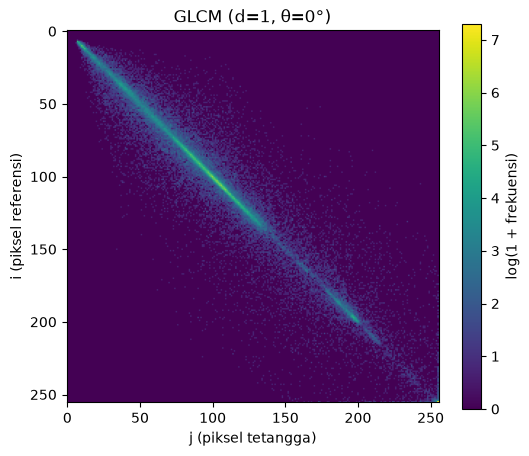


Fitur GLCM: {'contrast': np.float64(178.3333), 'energy': np.float64(0.0015), 'correlation': np.float64(0.9684), 'entropy': np.float64(11.4897), 'homogeneity': np.float64(0.4445)}


In [29]:
idx = 0
gray = citra_gray[idx + 1]
glcm = buat_glcm(gray)

print("Gambar :", df.loc[idx, "path"], "| label:", df.loc[idx, "label"])
print("Ukuran GLCM     :", glcm.shape)
print("Total pasangan  :", glcm.sum(), f"(= 256 baris x 255 pasangan per baris)")

n = 10
print(f"\nPotongan GLCM mentah ({n}x{n} pertama):")
print(pd.DataFrame(glcm[:n, :n]).to_string())

plt.figure(figsize=(6, 5))
plt.imshow(np.log1p(glcm), cmap="viridis")
plt.colorbar(label="log(1 + frekuensi)")
plt.title("GLCM (d=1, θ=0°)")
plt.xlabel("j (piksel tetangga)"); plt.ylabel("i (piksel referensi)")
plt.show()

print("\nFitur GLCM:", {k: round(v, 4) for k, v in fitur_glcm(glcm).items()})

In [30]:
hasil_glcm = []
for id_, gray in citra_gray.items():
    f = fitur_glcm(buat_glcm(gray))
    hasil_glcm.append({"id": id_, **{k: round(v, 6) for k, v in f.items()},
                       "label": df.loc[id_ - 1, "label"]})

tabel_glcm = pd.DataFrame(hasil_glcm)
tabel_glcm.to_csv("data/processed/fitur_glcm.csv", index=False)
print("Disimpan ke:", os.path.abspath("data/processed/fitur_glcm.csv"))
tabel_glcm

Disimpan ke: c:\project\image-classification\data\processed\fitur_glcm.csv


,id,contrast,energy,correlation,entropy,homogeneity,label
0,1,178.333303,0.001497,0.968367,11.489697,0.444492,berantakan
1,2,589.411811,0.000317,0.938569,13.031921,0.303823,berantakan
2,3,482.808042,0.000323,0.928412,12.863681,0.300613,berantakan
3,4,331.673698,0.000759,0.936609,12.109519,0.352516,berantakan
4,5,147.458640,0.001151,0.971639,11.153807,0.443736,berantakan
...,...,...,...,...,...,...,...
92,93,250.092540,0.001246,0.948009,11.625499,0.399390,berantakan
93,94,199.708900,0.001654,0.957219,11.169413,0.432666,berantakan
94,95,187.790303,0.005720,0.973014,10.695631,0.482297,berantakan
95,96,174.846247,0.001348,0.970058,11.498028,0.454084,berantakan
